In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\SHREYAS ROY\Desktop\Manipal Work Documents\seeds_data.csv")

rawFeatures = df.iloc[:, :-1].values.astype(np.float64)
targetLabels = df.iloc[:, -1].values.astype(int)

# Z Score Normalization
featureMean = np.mean(rawFeatures, axis=0)
featureStd = np.std(rawFeatures, axis=0)
featureStd[featureStd == 0] = 1e-8  

features = (rawFeatures - featureMean) / featureStd

In [12]:
def initializeKMeansCenters(features, numClusters):
    numSamples = features.shape[0]
    randomIndices = np.random.choice(numSamples, numClusters, replace=False)
    return features[randomIndices]

def runKMeans(features, numClusters=3, maxIterations=100, tolerance=1e-4):
    clusterCenters = initializeKMeansCenters(features, numClusters)
    
    for iteration in range(maxIterations):
        distances = np.linalg.norm(features[:, np.newaxis] - clusterCenters, axis=2)
        clusterLabels = np.argmin(distances, axis=1)
        
        newCenters = np.array([
            features[clusterLabels == i].mean(axis=0) if np.any(clusterLabels == i) else clusterCenters[i]
            for i in range(numClusters)
        ])
        
        if np.all(np.abs(newCenters - clusterCenters) < tolerance):
            break
        clusterCenters = newCenters
        
    return clusterCenters, clusterLabels

# Find optimal number of clusters using inertia (Elbow Method evaluation)
inertiaValues = []
clusterRange = range(1, 7)
for k in clusterRange:
    tempCenters, tempLabels = runKMeans(features, numClusters=k)
    distances = np.linalg.norm(features[:, np.newaxis] - tempCenters, axis=2)
    inertia = np.sum(np.min(distances, axis=1) ** 2)
    inertiaValues.append(inertia)

# Fit optimal K-Means model
optimalClusters = 3
kmeansCenters, kmeansLabels = runKMeans(features, numClusters=optimalClusters)

print("K-Means Results: ")
print(f"Final Cluster Centers:\n{kmeansCenters}")

K-Means Results: 
Final Cluster Centers:
[[-1.04419891 -1.01096544 -1.05792548 -0.88444994 -1.12588932  0.81282427
  -0.58376519]
 [-0.23074237 -0.26778746  0.41714637 -0.3635234  -0.07290447 -0.6460105
  -0.67525748]
 [ 1.21683723  1.22566876  0.53541683  1.2107643   1.12358058 -0.06261129
   1.26555784]]


In [14]:
def runDBSCAN(features, eps=1.2, minSamples=6):
    numSamples = features.shape[0]
    clusterLabels = np.full(numSamples, -2)  # NOTE: -2: unvisited, -1: noise, >=0: cluster id
    clusterId = 0
    
    distances = np.sqrt(np.sum((features[:, np.newaxis, :] - features[np.newaxis, :, :]) ** 2, axis=2))
    
    for i in range(numSamples):
        if clusterLabels[i] != -2:
            continue
        
        neighbors = np.where(distances[i] <= eps)[0]
        if len(neighbors) < minSamples:
            clusterLabels[i] = -1  # Mark as noise
        else:
            clusterLabels[i] = clusterId
            seedsList = list(neighbors)
            seedsList.remove(i)
            
            while len(seedsList) > 0:
                currentPoint = seedsList.pop(0)
                if clusterLabels[currentPoint] == -1:
                    clusterLabels[currentPoint] = clusterId
                if clusterLabels[currentPoint] != -2:
                    continue
                
                clusterLabels[currentPoint] = clusterId
                currentNeighbors = np.where(distances[currentPoint] <= eps)[0]
                if len(currentNeighbors) >= minSamples:
                    for neighbor in currentNeighbors:
                        if clusterLabels[neighbor] == -2 or clusterLabels[neighbor] == -1:
                            if clusterLabels[neighbor] == -2:
                                seedsList.append(neighbor)
                            clusterLabels[neighbor] = clusterId
            clusterId += 1
            
    numNoisePoints = np.sum(clusterLabels == -1)
    return clusterLabels, clusterId, numNoisePoints

# Fit DBSCAN with optimized hyperparameters on scaled features
optimalEps = 1.2
optimalMinSamples = 6
dbscanLabels, totalClustersFormed, totalNoisePoints = runDBSCAN(features, eps=optimalEps, minSamples=optimalMinSamples)

print("DBSCAN Results: ")
print(f"Number of clusters formed: {totalClustersFormed}")
print(f"Total number of noise/outlier points: {totalNoisePoints}")

DBSCAN Results: 
Number of clusters formed: 18
Total number of noise/outlier points: 11


In [15]:
def computePCA(features, numComponents=2):
    dataMean = np.mean(features, axis=0)
    centeredData = features - dataMean
    covarianceMatrix = np.cov(centeredData, rowvar=False)
    eigenvalues, eigenvectors = np.linalg.eigh(covarianceMatrix)
    
    sortedIndices = np.argsort(eigenvalues)[::-1]
    eigenvectors = eigenvectors[:, sortedIndices]
    
    projectionMatrix = eigenvectors[:, :numComponents]
    reducedData = np.dot(centeredData, projectionMatrix)
    return reducedData

reducedData = computePCA(features, numComponents=2)

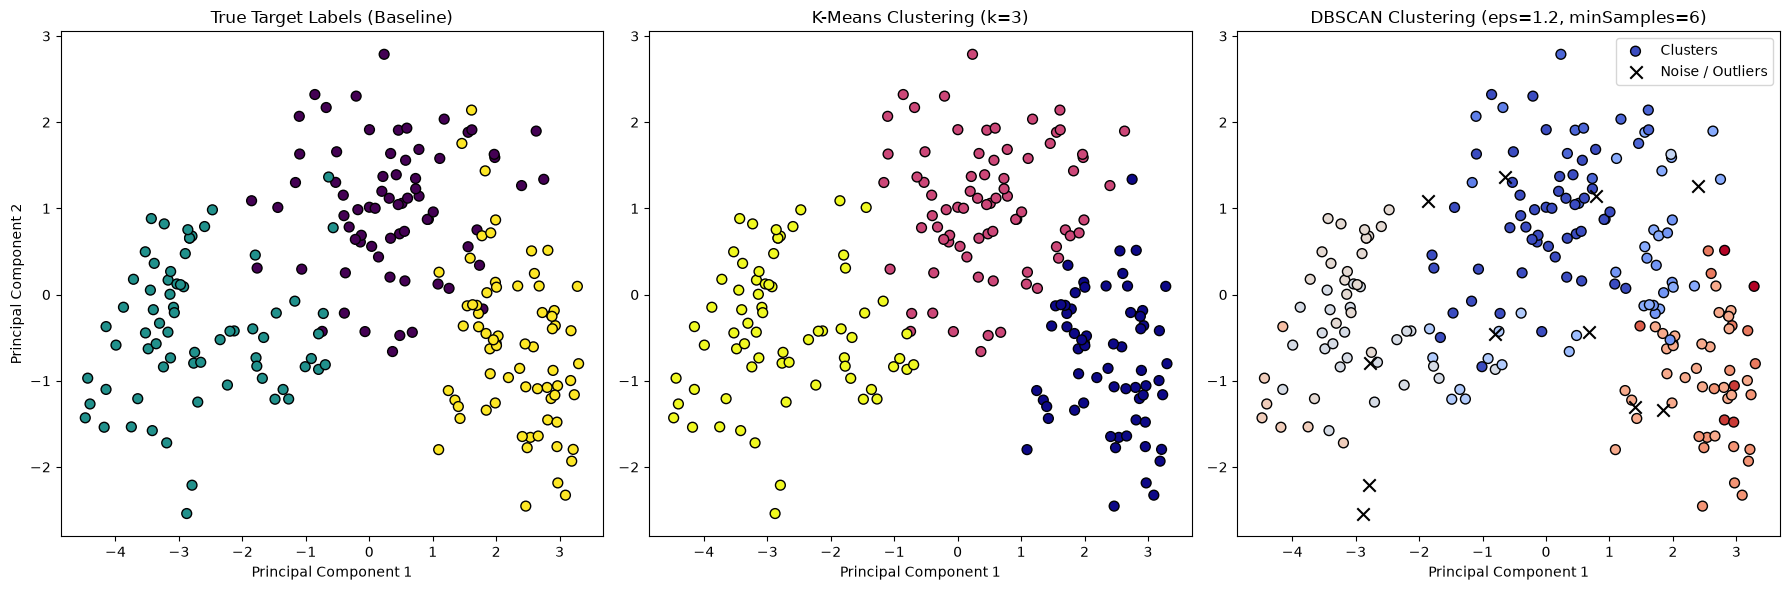

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# True Labels Baseline
axes[0].scatter(reducedData[:, 0], reducedData[:, 1], c=targetLabels, cmap='viridis', edgecolor='k', s=50)
axes[0].set_title("True Target Labels (Baseline)")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")

# K-Means Clustering
axes[1].scatter(reducedData[:, 0], reducedData[:, 1], c=kmeansLabels, cmap='plasma', edgecolor='k', s=50)
axes[1].set_title(f"K-Means Clustering (k={optimalClusters})")
axes[1].set_xlabel("Principal Component 1")

# DBSCAN Clustering (Distinct noise marker)
coreMask = dbscanLabels != -1
noiseMask = dbscanLabels == -1

axes[2].scatter(reducedData[coreMask, 0], reducedData[coreMask, 1], c=dbscanLabels[coreMask], cmap='coolwarm', edgecolor='k', s=50, label='Clusters')
axes[2].scatter(reducedData[noiseMask, 0], reducedData[noiseMask, 1], c='black', marker='x', s=80, label='Noise / Outliers')
axes[2].set_title(f"DBSCAN Clustering (eps={optimalEps}, minSamples={optimalMinSamples})")
axes[2].set_xlabel("Principal Component 1")
axes[2].legend()

plt.tight_layout()
plt.show()

In [23]:
def computeContingencyMatrix(trueLabels, predLabels):
    uniqueTrue = np.unique(trueLabels)
    uniquePred = np.unique(predLabels)
    
    trueToIdx = {val: i for i, val in enumerate(uniqueTrue)}
    predToIdx = {val: i for i, val in enumerate(uniquePred)}
    
    contingency = np.zeros((len(uniqueTrue), len(uniquePred)), dtype=int)
    for t, p in zip(trueLabels, predLabels):
        contingency[trueToIdx[t], predToIdx[p]] += 1
        
    return contingency, uniqueTrue, uniquePred

def computeClusterPurity(trueLabels, predLabels):
    contingency, _, _ = computeContingencyMatrix(trueLabels, predLabels)
    return np.sum(np.max(contingency, axis=0)) / np.sum(contingency)

def computeAdjustedRandIndex(trueLabels, predLabels):
    contingency, _, _ = computeContingencyMatrix(trueLabels, predLabels)
    
    sumCombC = np.sum(contingency * (contingency - 1) / 2)
    sumCombRow = np.sum(np.sum(contingency, axis=1) * (np.sum(contingency, axis=1) - 1) / 2)
    sumCombCol = np.sum(np.sum(contingency, axis=0) * (np.sum(contingency, axis=0) - 1) / 2)
    
    totalPairs = len(trueLabels) * (len(trueLabels) - 1) / 2
    
    expectedIndex = (sumCombRow * sumCombCol) / totalPairs
    maxIndex = (sumCombRow + sumCombCol) / 2
    
    if maxIndex == expectedIndex:
        return 0.0
        
    ari = (sumCombC - expectedIndex) / (maxIndex - expectedIndex)
    return ari

kmeansPurity = computeClusterPurity(targetLabels, kmeansLabels)
kmeansAri = computeAdjustedRandIndex(targetLabels, kmeansLabels)

# Ignoring noise points labeled as -1 for purity calculation, or evaluating them separately
validMask = dbscanLabels != -1
if np.sum(validMask) > 0:
    dbscanPurity = computeClusterPurity(targetLabels[validMask], dbscanLabels[validMask])
    dbscanAri = computeAdjustedRandIndex(targetLabels[validMask], dbscanLabels[validMask])
else:
    dbscanPurity = 0.0
    dbscanAri = 0.0

print("Quantitative Baseline Comparison: ")
print(f"K-Means Clustering Purity against True Labels: {kmeansPurity:.4f}")
print(f"K-Means ARI: {kmeansAri:.4f}")
print(f"DBSCAN Clustering Purity (valid points) against True Labels: {dbscanPurity:.4f}")
print(f"DBSCAN Noise Ratio: {totalNoisePoints / len(targetLabels):.4f} ({totalNoisePoints} out of {len(targetLabels)} points)")

Quantitative Baseline Comparison: 
K-Means Clustering Purity against True Labels: 0.9190
K-Means ARI: 0.7730
DBSCAN Clustering Purity (valid points) against True Labels: 0.9045
DBSCAN Noise Ratio: 0.0524 (11 out of 210 points)
